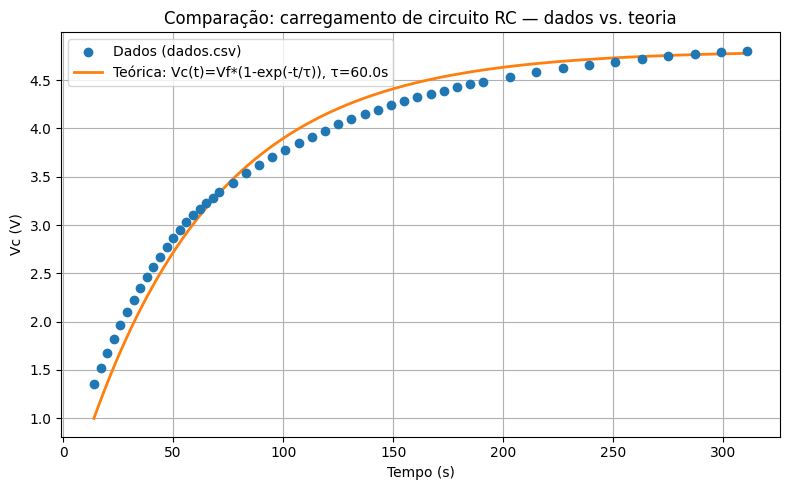

In [3]:
import pandas as pd
import numpy as np

# Código para ler 'dados.csv' e plotar comparação entre dados experimentais e função teórica
import matplotlib.pyplot as plt

# parâmetros teóricos
tau = 60.0  # constante de tempo τ
csv_file = "dados.csv"

# ler arquivo
df = pd.read_csv(csv_file)

# detectar colunas de tempo e tensão (aceita vários nomes comuns)
cols_lower = [c.lower() for c in df.columns]
time_candidates = ['t', 'time', 'tempo']
voltage_candidates = ['vc', 'v_c', 'vcap', 'v', 'voltage', 'tensão', 'tensao']

time_col = next((df.columns[i] for i, c in enumerate(cols_lower) if c in time_candidates), None)
voltage_col = next((df.columns[i] for i, c in enumerate(cols_lower) if c in voltage_candidates), None)

# se não encontrar, assumir primeira coluna = tempo, segunda = tensão
if time_col is None:
    time_col = df.columns[0] if df.shape[1] >= 1 else None
if voltage_col is None:
    voltage_col = df.columns[1] if df.shape[1] >= 2 else (df.columns[0] if df.shape[1] == 1 else None)

if time_col is None or voltage_col is None:
    raise ValueError("Não foi possível identificar colunas de tempo e tensão em 'dados.csv'. Verifique o arquivo.")

t = df[time_col].to_numpy(dtype=float)
Vc_meas = df[voltage_col].to_numpy(dtype=float)

# estimar Vf: se houver coluna 'Vf' ou 'vf' use-a, senão usar valor máximo medido
vf_col = next((df.columns[i] for i, c in enumerate(cols_lower) if c == 'vf'), None)
if vf_col:
    Vf = float(df[vf_col].iloc[0])
else:
    Vf = float(np.nanmax(Vc_meas))

# calcular curva teórica em uma malha fina de tempo
t_fit = np.linspace(np.min(t), np.max(t), 500)
Vc_theor = Vf * (1 - np.exp(-t_fit / tau))

# plot
plt.figure(figsize=(8,5))
plt.scatter(t, Vc_meas, color='C0', label='Dados (dados.csv)', zorder=3)
plt.plot(t_fit, Vc_theor, color='C1', linewidth=2, label=f'Teórica: Vc(t)=Vf*(1-exp(-t/τ)), τ={tau}s')
plt.xlabel('Tempo (s)')
plt.ylabel('Vc (V)')
plt.title('Comparação: carregamento de circuito RC — dados vs. teoria')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()